<a href="https://colab.research.google.com/github/RinaDinosaur/cpp-practice-2026/blob/main/26_11_Miroshnikova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!apt-get update -qq
!apt-get install -y g++ libopencv-dev libcurl4-openssl-dev

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
g++ is already the newest version (4:13.2.0-7ubuntu1).
g++ set to manually installed.
libcurl4-openssl-dev is already the newest version (8.5.0-2ubuntu10.16).
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  libgstreamer-plugins-base1.0-0 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libgudev-1

In [2]:
%%writefile detect_faces.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <opencv2/objdetect.hpp>
#include <curl/curl.h>

size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

std::vector<uchar> download(const std::string& url) {
    std::vector<uchar> data;
    CURL* curl = curl_easy_init();
    if (curl) {
        curl_easy_setopt(curl, CURLOPT_URL, url.c_str());
        curl_easy_setopt(curl, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl, CURLOPT_WRITEDATA, &data);
        curl_easy_setopt(curl, CURLOPT_FOLLOWLOCATION, 1L);
        curl_easy_setopt(curl, CURLOPT_USERAGENT, "libcurl-agent/1.0");
        curl_easy_perform(curl);
        curl_easy_cleanup(curl);
    }
    return data;
}

cv::Mat loadImage(const std::string& source) {
    if (source.rfind("http", 0) == 0) {
        auto bytes = download(source);
        return cv::imdecode(bytes, cv::IMREAD_COLOR);
    }
    return cv::imread(source);
}

int main(int argc, char** argv) {
    std::string source = (argc > 1) ? argv[1]
        : "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg";

    std::cout << "Loading: " << source << std::endl;
    cv::Mat image = loadImage(source);
    if (image.empty()) {
        std::cerr << "Failed to load image from: " << source << std::endl;
        return 1;
    }
    std::cout << "Image: " << image.cols << "x" << image.rows << std::endl;

    cv::CascadeClassifier face_cascade, eye_cascade;
    if (!face_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml") ||
        !eye_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_eye.xml")) {
        std::cerr << "Cannot load cascades" << std::endl;
        return 1;
    }

    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);
    cv::equalizeHist(gray, gray);

    std::vector<cv::Rect> faces;
    face_cascade.detectMultiScale(gray, faces, 1.05, 5, 0, cv::Size(20, 20));

    std::cout << "Detected faces: " << faces.size() << std::endl;

    int total_eyes = 0;
    int idx = 0;
    for (const auto& face : faces) {
        ++idx;
        cv::rectangle(image, face, cv::Scalar(0, 255, 0), 2);

        std::string label = "Face " + std::to_string(idx);
        int baseline = 0;
        cv::Size text_size = cv::getTextSize(label, cv::FONT_HERSHEY_SIMPLEX, 0.6, 2, &baseline);
        cv::Point text_org(face.x, face.y - 5);
        if (text_org.y < text_size.height) text_org.y = face.y + text_size.height + 5;

        cv::rectangle(image,
                      cv::Point(text_org.x, text_org.y - text_size.height - 2),
                      cv::Point(text_org.x + text_size.width, text_org.y + 2),
                      cv::Scalar(0, 255, 0), cv::FILLED);
        cv::putText(image, label, text_org, cv::FONT_HERSHEY_SIMPLEX, 0.6,
                    cv::Scalar(0, 0, 0), 2);

        cv::Mat face_roi_gray = gray(face);
        cv::Mat face_roi_gray_top = face_roi_gray(cv::Rect(0, 0, face.width, face.height * 6 / 10));

        std::vector<cv::Rect> eyes;
        eye_cascade.detectMultiScale(face_roi_gray_top, eyes, 1.1, 10);
        total_eyes += eyes.size();
        for (const auto& eye : eyes) {
            cv::Rect eye_abs(face.x + eye.x, face.y + eye.y, eye.width, eye.height);
            cv::rectangle(image, eye_abs, cv::Scalar(255, 0, 0), 2);
        }
    }

    std::cout << "Detected eyes: " << total_eyes << std::endl;

    cv::imwrite("faces_detected.jpg", image);
    std::cout << "Result saved: faces_detected.jpg" << std::endl;

    if (faces.empty()) {
        std::cerr << "No faces detected." << std::endl;
        return 2;
    }
    return 0;
}

Writing detect_faces.cpp


In [3]:
!g++ detect_faces.cpp -o detect_faces $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17

In [4]:
from google.colab import files
uploaded = files.upload()

print("\nЗагруженные файлы:")
for name in uploaded.keys():
    print("имя:", name, "| адрес:", "/content/" + name)

Saving ctct.jpg to ctct (1).jpg

Загруженные файлы:
имя: ctct (1).jpg | адрес: /content/ctct (1).jpg


In [9]:
# Эксперимент 1
!./detect_faces ctct.jpg
!cp faces_detected.jpg result_1.jpg



Loading: ctct.jpg
Image: 1280x721
Detected faces: 4
Detected eyes: 0
Result saved: faces_detected.jpg


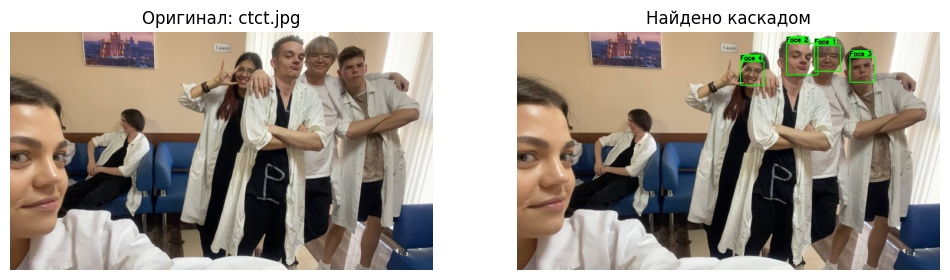

In [10]:
import cv2
import matplotlib.pyplot as plt

# Берем твое оригинальное фото и то, что сделала C++ программа
orig = cv2.imread('ctct.jpg')
res = cv2.imread('result_1.jpg')

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
axes[0].set_title('Оригинал: ctct.jpg')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(res, cv2.COLOR_BGR2RGB))
axes[1].set_title('Найдено каскадом')
axes[1].axis('off')

plt.show()

In [11]:
# Эксперимент 2
!./detect_faces group.jpg
!cp faces_detected.jpg result_2.jpg

Loading: group.jpg
Image: 1242x2208
Detected faces: 17
Detected eyes: 0
Result saved: faces_detected.jpg


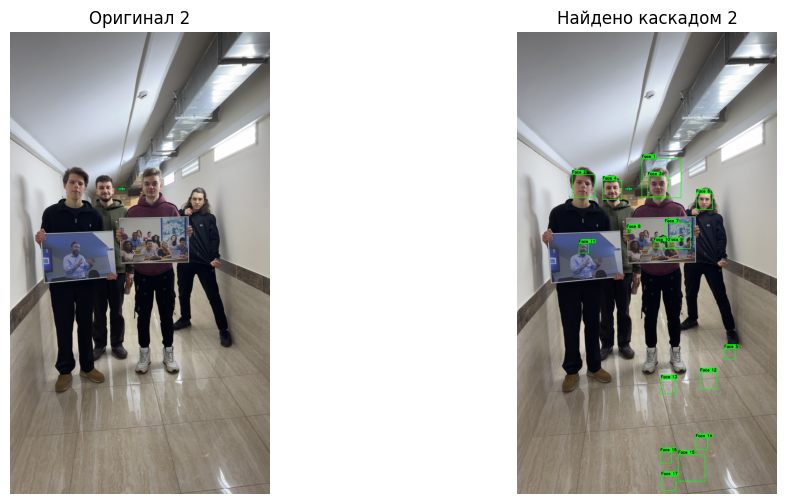

In [12]:
orig = cv2.imread('group.jpg')
res = cv2.imread('result_2.jpg')

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
axes[0].set_title('Оригинал 2')
axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(res, cv2.COLOR_BGR2RGB))
axes[1].set_title('Найдено каскадом 2')
axes[1].axis('off')
plt.show()

## Сравнение и почему не всё распознаётся

| Фото | Лиц на фото (глазами) | Найдено лиц | Глаз на фото | Найдено глаз |
|------|----------------------|-------------|--------------|--------------|
| 1    | 5                  | 4         | 10          | 0          |
| 2    | 4                  | 17         | 8          | 0          |


### Почему каскады Хаара находят не всё

1. Каскад обучен только на фронтальные лица. Лицо в профиль, повёрнутое или наклонённое - часто не находится.
2. В коде стоит `minSize = (20, 20)`. Лица меньше 20 px по стороне не ищутся вообще.
3. Плохое освещение, размытие, шум — признаки (перепады яркости), на которых работает каскад, становятся слабыми.
4.  Очки, маска, рука, волосы, тень — часть лица закрыта, каскад не срабатывает.
5. Групповые фото:лица перекрывают друг друга, `minNeighbors = 5` может отбросить настоящие лица как ложные.
6. Глаза ищутся только в верхних 60% лица (`face.height * 6 / 10`). При наклоне головы глаза могут выйти за эту область - и не найдутся даже при идеальном лице.
7. Закрытые глаза, тёмные очки, низкое разрешение — каскад `haarcascade_eye` их не видит.
8. Баланс параметров. `scaleFactor = 1.05` и `minNeighbors = 5` — это компромисс. Меньше `minNeighbors` → больше находок, но и больше ложных срабатываний. Больше → строже, но пропусков больше.

### Вывод

Каскады Хаара — старый и быстрый, но не очень точный метод. На простых фронтальных фото он работает почти идеально. На групповых, профильных, с очками или плохим светом — часть лиц и глаз теряется. Это ограничение самого алгоритма: он ищет только те признаки, на которых его обучали.